# 10 · Idea A — Carry (original) and flip carry (adopted candidate)

**原始 A 状态：** closed negative。A 在 v2 口径下 gross 已经为负，扣成本后更负；
原始方向不再调参或做 rescue 变体。v2 正式结果不变。

**采用候选信号：** `target_flip = -sign(spread_dollar)`：contango → long spread，
backwardation → short spread（D-025，见 §7）。§7 是 gross-only 的信号信息检验，
交易成本留到最终 portfolio；这不是对 A 的 rescue。

本 notebook 只负责一个 idea。§4–§6 的 PnL、持仓和 overall Sharpe 都来自 v2 正式口径；
§7 是新信号的诊断，两者不能混表。历史 v1 内容见 `docs/a_negative_result.md` 和
`docs/notebook_history.md`。

## 1. 约定 / Conventions

- 正式结果使用 v2 holdings-based simulator（D-019）。
- 口径：`d=5`、`k=5`、`min_adv=100`、USD 10m capital、equal-notional、
  三层成本（half-spread / fees / impact），见 D-018。
- PnL 曲线：`F.nav_by_cost_layer`，gross 加上三层成本，阴影是 2016 年起的
  post-hoc test sample。
- Overall Sharpe：full sample 1986–2026 的 **all-in net** 日收益，rf=0，
  252 天年化；每个 notebook 只报这一个 Sharpe。
- 持仓热力图：方向取最近到期腿（蓝=多，橙=空，白=空仓），大小是该品种的
  gross notional / capital；下图是组合 gross exposure 和年化换手。
- §7 的 flip 检验是 gross、execution-free、equal-notional 0.5x；
  正式 A 的 PnL/Sharpe 仍是 v2 all-in net，两者不能混表。

## 2. 环境与数据 / Setup


In [1]:
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import (
    config,
    diagnostics as diag,
    figures as F,
    horizon,
    plotstyle as ps,
    report,
    signals,
    v2_signals,
    v2_rerun,
)

logging.getLogger("fontTools").setLevel(logging.ERROR)
ps.use()
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
OUT = config.OUTPUT_DIR / "v2_rerun"
OUT.mkdir(parents=True, exist_ok=True)
ROOT_ORDER = (
    rank[["root", "sector"]]
    .drop_duplicates()
    .sort_values(["sector", "root"])["root"]
    .tolist()
)
rank.shape

(1013664, 23)

## 3. 运行 / Run


In [2]:
inputs = v2_signals.load_v2_inputs(rank, d=5, k=5, min_adv=100)
item = v2_rerun.run_strategy("a", rank, inputs=inputs)
v2_rerun.save_strategy(item, OUT)
res = item["result"]
print("saved:", OUT / "a_performance.csv", OUT / "a_root.csv")

saved: /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/.claude/worktrees/a-flip-diag/output/v2_rerun/a_performance.csv /Users/tian/Library/Mobile Documents/com~apple~CloudDocs/Baruch/第三学期/Systematic Trading/Project/.claude/worktrees/a-flip-diag/output/v2_rerun/a_root.csv


## 4. Full-sample 总览 / Headline


In [3]:
full = item["performance"].xs("full", level="period").set_index("layer")
display(
    full[["ann_ret_pct", "ann_vol_pct", "max_dd_pct", "turnover_x"]]
    .round(3)
    .rename(columns={
        "ann_ret_pct": "Ann. ret (%)",
        "ann_vol_pct": "Ann. vol (%)",
        "max_dd_pct": "Max DD (%)",
        "turnover_x": "Turnover (x/yr)",
    })
)
print(f"Overall Sharpe (full sample, all-in net): {report.overall_sharpe(res):+.3f}")


,Ann. ret (%),Ann. vol (%),Max DD (%),Turnover (x/yr)
layer,,,,
gross,-0.484,0.957,-24.239,26.133
- half-spread,-0.843,0.958,-38.224,26.133
- fees,-1.002,0.959,-44.462,26.133
- impact (all),-2.610,1.006,-109.099,26.133


Overall Sharpe (full sample, all-in net): -2.595


## 5. PnL 曲线 / Cumulative PnL


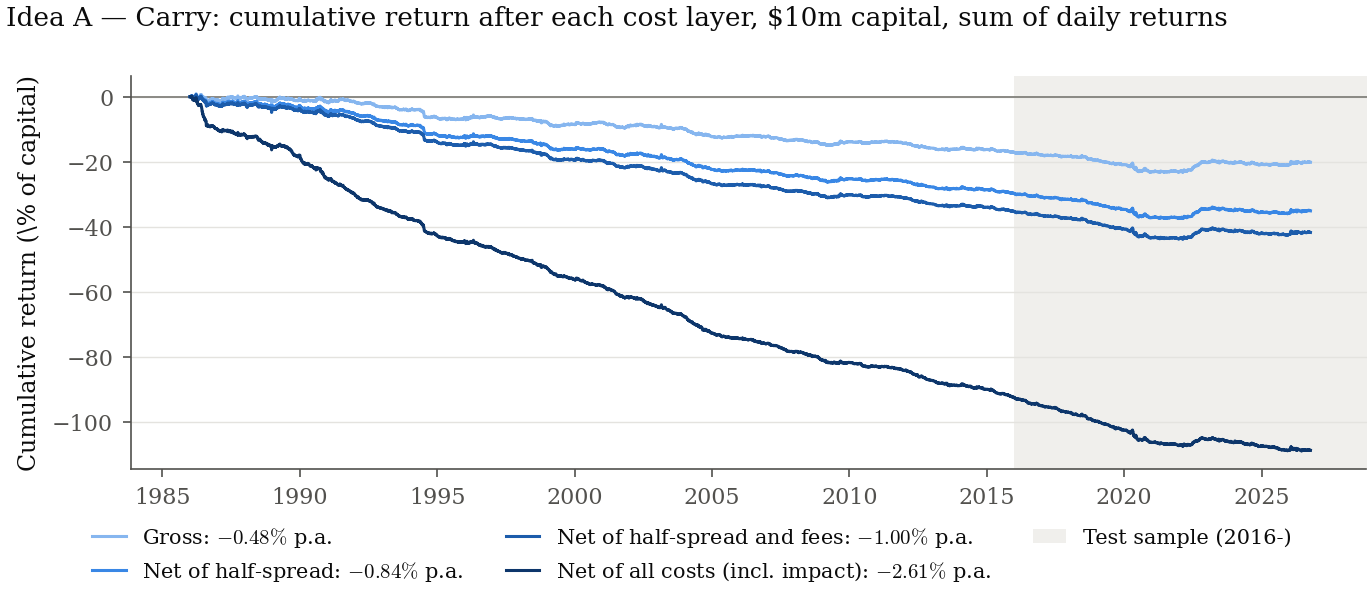

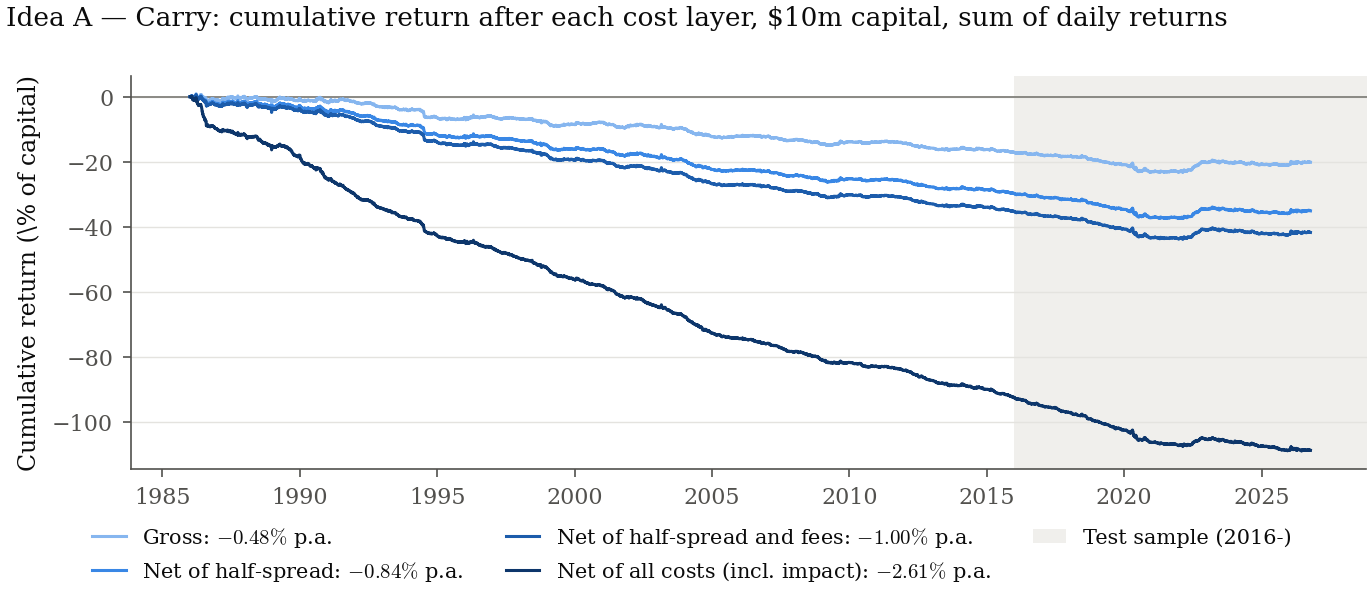

In [4]:
fig = F.nav_by_cost_layer(res, "Idea A — Carry")
ps.save(fig, "idea_a_pnl")
display(fig)


## 6. 持仓变化 / Positions


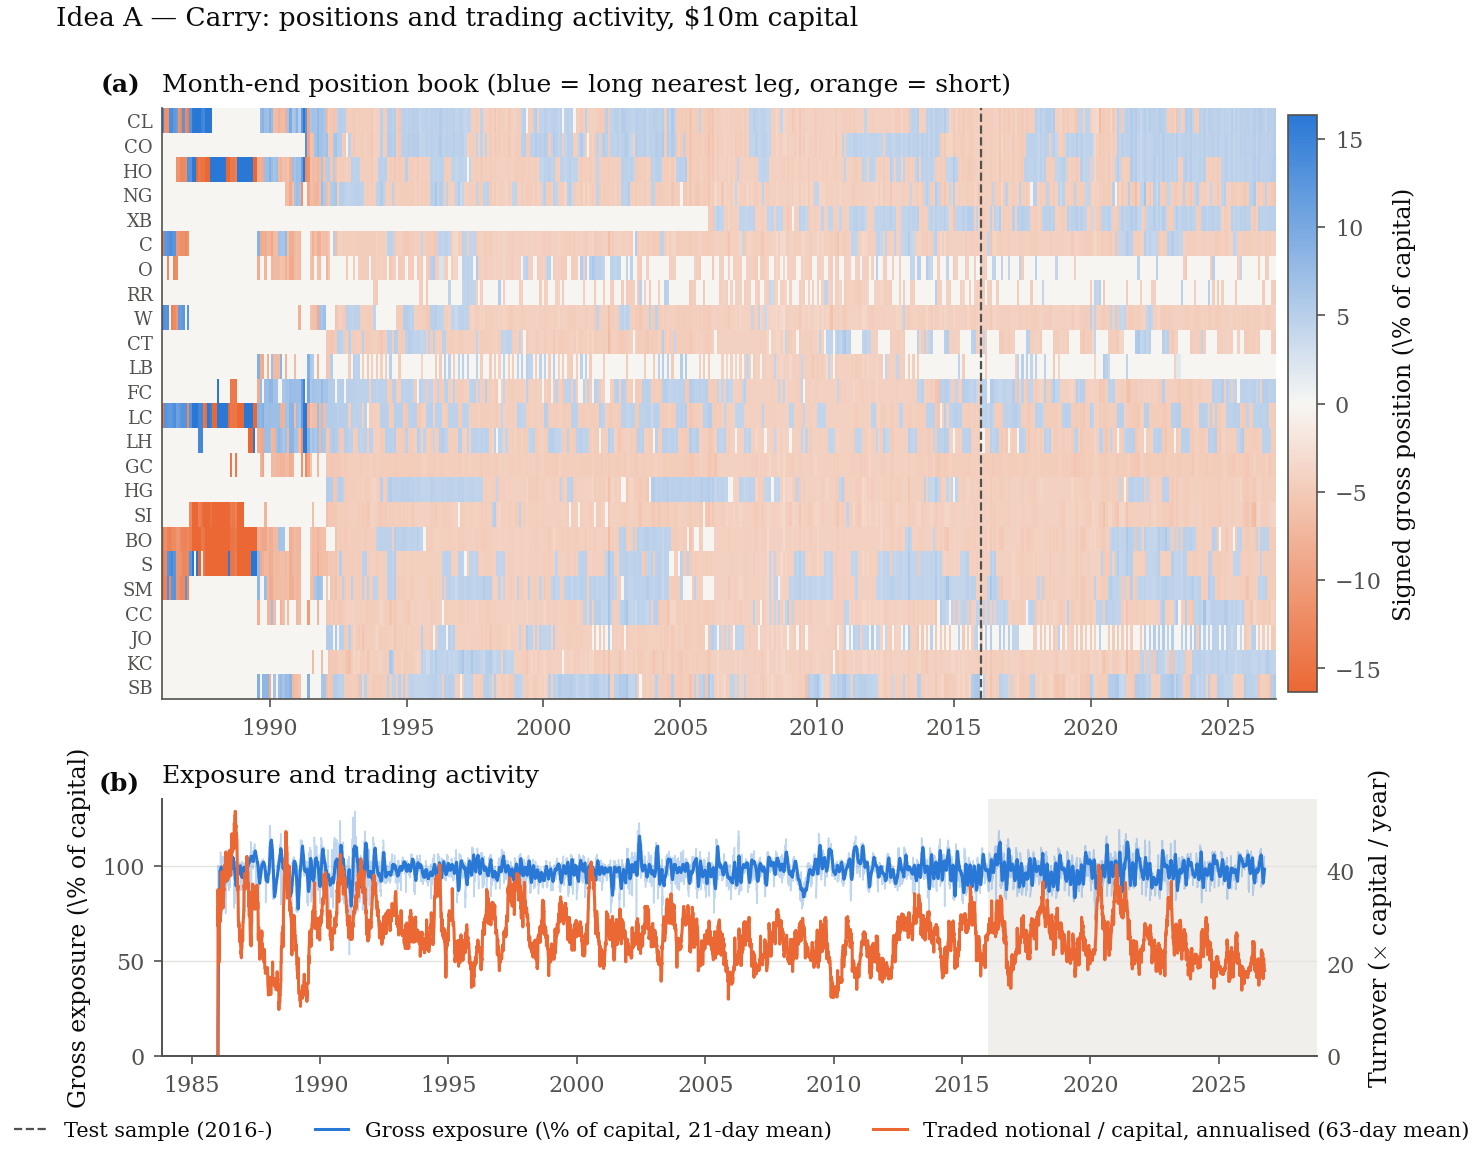

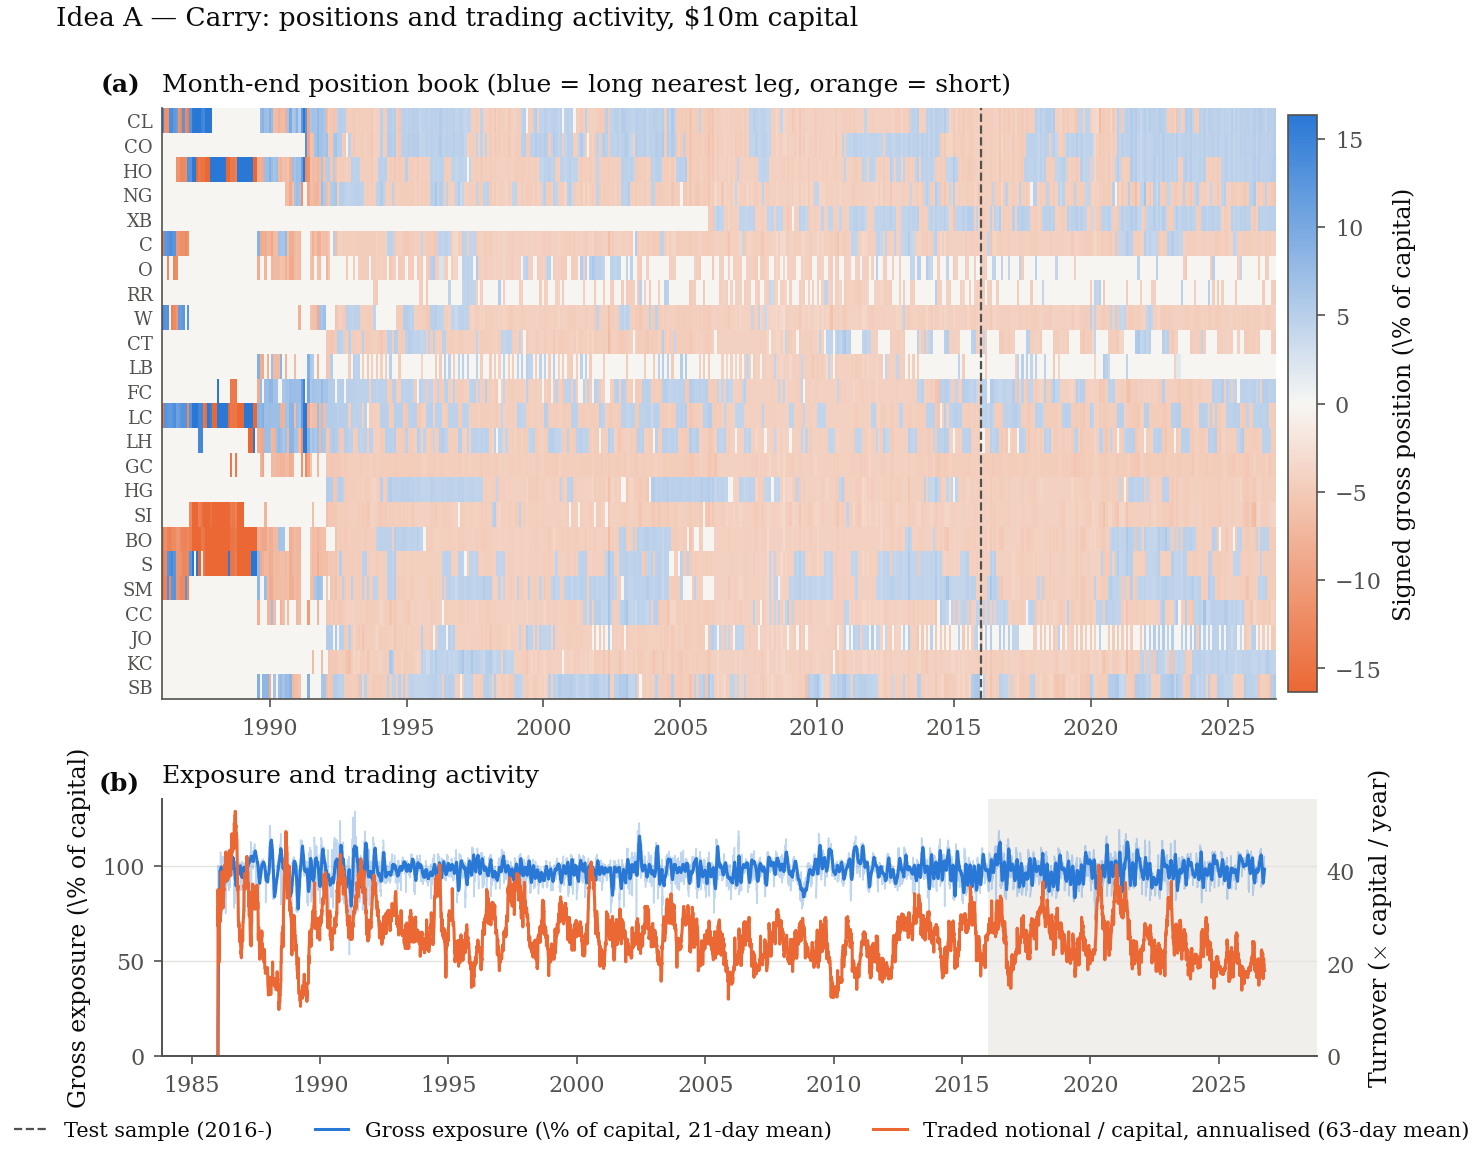

In [5]:
panel = F.position_panel(res, root_order=ROOT_ORDER)
panel.to_csv(OUT / "a_positions_month_end.csv")
fig = F.positions(res, "Idea A — Carry", root_order=ROOT_ORDER)
ps.save(fig, "idea_a_positions")
display(fig)


## 7. Flip carry 信息诊断 / Signal-information diagnostics

原始 A 的方向（backwardation long / contango short）是 documented negative。
数据的方向相反，尤其是 contango short。这里检验一个新的、固定的信号假设：

`target_flip = -sign(spread_dollar)`：**contango → long spread；
backwardation → short spread**。

这不是 A 的 rescue，也不改变 §4–§6 的官方 A 结果。First pass 只用默认参数，
不调 threshold / lookback / holding period / pair / cost：

| 项目 | 取值 |
|---|---|
| Universe | `d=5`, `k=5`, `min_adv=100`；`inputs.pairs` |
| Signal | `CarryParams(signal="dollar_sign", annualize_days="delivery_month")` |
| Daily | `fwd_1_2`（t+1 fill, t+1→t+2） |
| 5-day information | `fwd_1_6`（t+1→t+6） |
| Horizon scan | `DEFAULT_HORIZONS` + 1–20 day marginal/cumulative |
| IC | `min_obs=252` |
| Bins | 5 bins, `min_history=252` |
| Bootstrap | `block=21`, `n_boot=2000`, `seed=0` |

**符号：** `carry_ann` 是原始 annualized carry（backwardation 为正）；
flip 的连续 score 是 `score_flip = -carry_ann`（contango 为正），所以
**正 IC 支持 flip**。`target_flip` 在 contango 为正、backwardation 为负。

**Liquidity：** 信息检验只使用 `inputs.pairs["liquid"]` 且两条腿价格 > 0 的
pair-date，与 `sizing.legs_from_signal` 的交易 universe 一致；`~tradable`
的 target 设为 0，`score_flip` 设为 NaN。预期约 203k / 236k。

**Scale：** §7.1 的 horizon table 和 §7.2 的 decay figure 是 **1x spread
return**；equal-notional portfolio return 是它的 0.5x。§7.5–§7.7 的 signed
return / Sharpe / MDE 已经是 **0.5x**。两类数字不混表。

In [6]:
pairs = inputs.pairs.copy().reset_index(drop=True)
sig = signals.carry_signal(pairs)
assert sig["date"].equals(pairs["date"]) and sig["root"].equals(pairs["root"])
sig["target_flip"] = -sig["target"]
sig["score_flip"] = -sig["carry_ann"]

tradable = (
    pairs["liquid"].to_numpy()
    & pairs["settle_near"].gt(0).to_numpy()
    & pairs["settle_far"].gt(0).to_numpy()
)
sig.loc[~tradable, ["target", "target_flip"]] = 0.0
sig.loc[~tradable, "score_flip"] = np.nan
sig_flip = sig[["date", "root"]].assign(
    target=sig["target_flip"], score=sig["score_flip"], carry_ann=sig["carry_ann"]
)

fwd = horizon.forward_returns(pairs, inputs.marks, horizons=horizon.DEFAULT_HORIZONS)

print(f"pair-dates: {len(pairs):,}; tradable: {tradable.sum():,}")
display(sig["target_flip"].value_counts().rename("pair-dates").to_frame())

pair-dates: 236,321; tradable: 203,356


,pair-dates
target_flip,
1.0,140220
-1.0,61915
0.0,34186


### 7.1 Signed horizon profile

`mean_bps` 是 **1x** 的 `target_flip × (r_near − r_far)`，pair 固定在 t；
equal-notional portfolio return 要乘 0.5。Horizon：
`t+1→t+2`（day 1）、`t+1→t+3`（2d）、`t+1→t+4`（3d）、`t+1→t+6`（5d）、
`t+1→t+11`（10d）、`t+1→t+21`（20d）、`t+11→t+21`（days 11–20）。
t-stat 是 Newey–West，lag = window length。full 是 descriptive；test 是
confirmatory slice。

In [7]:
prof = diag.horizon_profile_by_period(fwd, sig, score_col="target_flip")
display(prof.pivot(index="horizon", columns="period", values="mean_bps").round(3))
display(prof.pivot(index="horizon", columns="period", values="t_nw").round(2))
display(prof.pivot(index="horizon", columns="period", values="hit_rate").round(3))

period,full,test 2016-2026,train 1986-2015
horizon,,,
t+1->t+11,3.351,3.525,3.288
t+1->t+2,0.501,0.361,0.551
t+1->t+21,7.585,8.931,7.102
t+1->t+3,0.831,0.573,0.924
t+1->t+4,1.053,0.878,1.116
t+1->t+6,1.300,1.099,1.373
t+11->t+21,4.149,3.256,4.470


period,full,test 2016-2026,train 1986-2015
horizon,,,
t+1->t+11,3.83,1.67,3.59
t+1->t+2,4.17,1.63,3.87
t+1->t+21,4.61,2.36,3.99
t+1->t+3,4.02,1.37,3.90
t+1->t+4,3.61,1.44,3.37
t+1->t+6,2.68,0.98,2.63
t+11->t+21,4.06,1.39,4.05


period,full,test 2016-2026,train 1986-2015
horizon,,,
t+1->t+11,0.507,0.513,0.504
t+1->t+2,0.484,0.484,0.483
t+1->t+21,0.525,0.527,0.524
t+1->t+3,0.494,0.496,0.494
t+1->t+4,0.495,0.496,0.494
t+1->t+6,0.498,0.502,0.497
t+11->t+21,0.529,0.533,0.528


### 7.2 Marginal vs cumulative

Marginal 是 `[t+h, t+h+1]` 的单日收益；cumulative 是 `[t+1, t+1+h]` 的
累计收益。两者都是 **1x** spread return，pair 固定在 t；equal-notional
portfolio return 要乘 0.5。

,horizon,mean_bps,t_nw,hit_rate
0,t+1->t+2,0.50,4.17,0.48
1,t+2->t+3,0.33,2.68,0.48
2,t+3->t+4,0.23,1.82,0.48
3,t+4->t+5,0.17,0.96,0.48
4,t+5->t+6,0.01,0.03,0.49
5,t+6->t+7,0.12,0.66,0.49
6,t+7->t+8,0.20,1.04,0.49
7,t+8->t+9,0.06,0.30,0.49
8,t+9->t+10,0.13,0.68,0.49
9,t+10->t+11,0.24,1.24,0.49


,horizon,mean_bps,t_nw,hit_rate
0,t+1->t+2,0.50,4.17,0.48
1,t+1->t+3,0.83,4.02,0.49
2,t+1->t+4,1.05,3.61,0.49
3,t+1->t+5,1.19,3.02,0.50
4,t+1->t+6,1.30,2.68,0.50
5,t+1->t+7,1.72,3.03,0.50
6,t+1->t+8,2.21,3.41,0.50
7,t+1->t+9,2.45,3.42,0.50
8,t+1->t+10,2.84,3.57,0.50
9,t+1->t+11,3.35,3.83,0.51


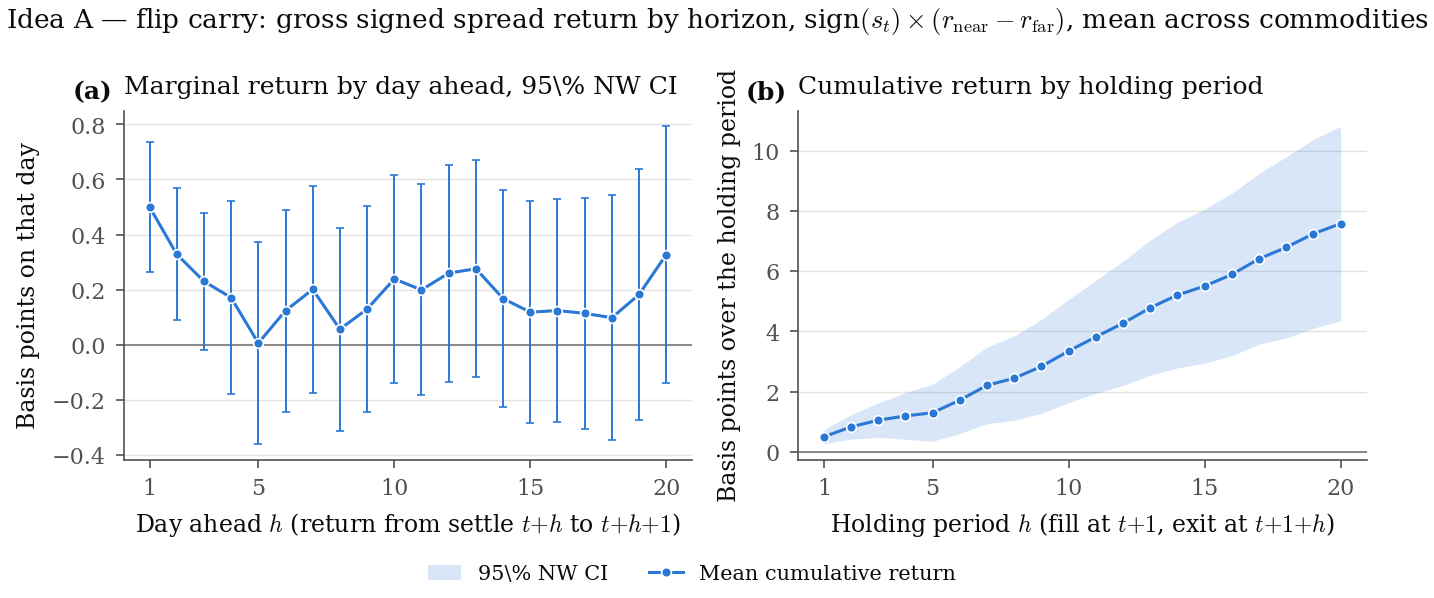

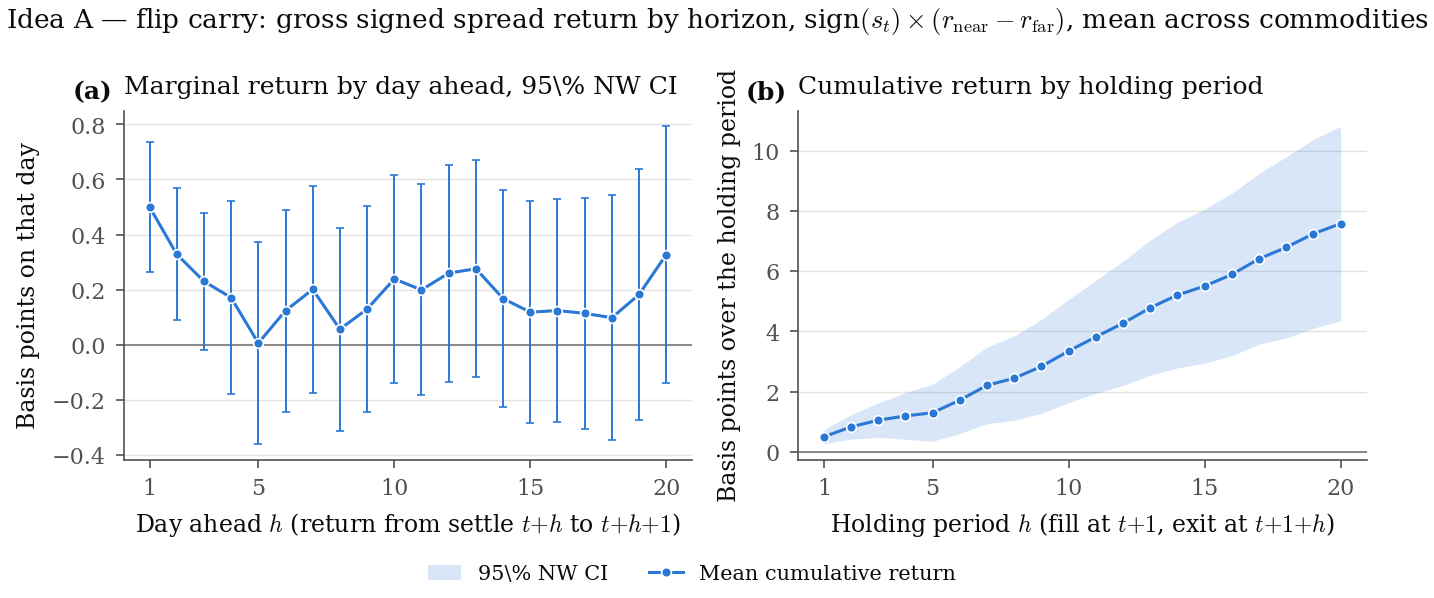

In [8]:
fwd_marg = horizon.forward_returns(pairs, inputs.marks, horizons=horizon.marginal_horizons(20))
fwd_cum = horizon.forward_returns(pairs, inputs.marks, horizons=horizon.cumulative_horizons(20))
marg = diag.horizon_profile_by_period(fwd_marg, sig, score_col="target_flip")
cum = diag.horizon_profile_by_period(fwd_cum, sig, score_col="target_flip")
marg_full = marg.loc[marg["period"].eq("full")].reset_index(drop=True)
cum_full = cum.loc[cum["period"].eq("full")].reset_index(drop=True)
display(marg_full[["horizon", "mean_bps", "t_nw", "hit_rate"]].round(2))
display(cum_full[["horizon", "mean_bps", "t_nw", "hit_rate"]].round(2))
fig = F.horizon_decay(marg_full, cum_full, "Idea A — flip carry")
ps.save(fig, "idea_a_flip_horizon_decay")
display(fig)

### 7.3 IC and own-history bins

IC 用 `score_flip = -carry_ann`（正值 = contango），所以 **正 IC 支持 flip**。
`ts_ic` 的 ALL 行是 24 个 root IC 的等权平均，没有 t-stat；显著性看 §7.4 的
per-root bootstrap。分箱按 `score_flip` 的 own-history expanding quintile：
Q1 = 最 backwardation，Q5 = 最 contango；表里是 **raw** `fwd_1_6`，不是
signed return，所以 Q1→Q5 递增支持 flip。`bins_by_period` 在每个 period
起点重置 expanding percentile；full-sample bins 是 primary，train/test bins
是 caveated。

In [9]:
ic = diag.ic_by_period(fwd, sig, score_col="score_flip", col="fwd_1_6", min_obs=252)
display(ic.loc[ic["root"].eq("ALL")].round(3))
display(
    ic.loc[~ic["root"].eq("ALL")]
    .groupby("period")["ic"]
    .agg(["mean", "median", "count"])
    .round(3)
)
bins = diag.bins_by_period(
    fwd, sig, score_col="score_flip", col="fwd_1_6", n_bins=5, min_history=252
)
display(bins.pivot(index="bin", columns="period", values="mean_bps").round(2))

,root,ic,t_nw,n,period
24,ALL,0.048,NaN,203356,full
49,ALL,0.045,NaN,145565,train 1986-2015
74,ALL,0.071,NaN,57791,test 2016-2026


,mean,median,count
period,,,
full,0.048,0.051,24
test 2016-2026,0.071,0.062,24
train 1986-2015,0.045,0.040,24


period,full,test 2016-2026,train 1986-2015
bin,,,
1,-1.08,2.42,-0.75
2,1.87,0.10,2.56
3,1.38,-0.74,1.93
4,1.67,1.47,1.56
5,4.88,5.21,3.87


### 7.4 Block bootstrap IC

每个 root 做 21-day moving-block bootstrap（2000 draws），保留 overlapping
forward window 和 persistent score 的序列相关。24 个 root 高度相关，不能把
“p<0.05 的 root 数”当成 24 次独立确认；报告分布、median 和 p<0.05 的个数，
不挑最好的 root。

,n_roots,n_sig,median_ic
period,,,
full,24,11,0.051
test 2016-2026,24,8,0.062
train 1986-2015,24,10,0.040


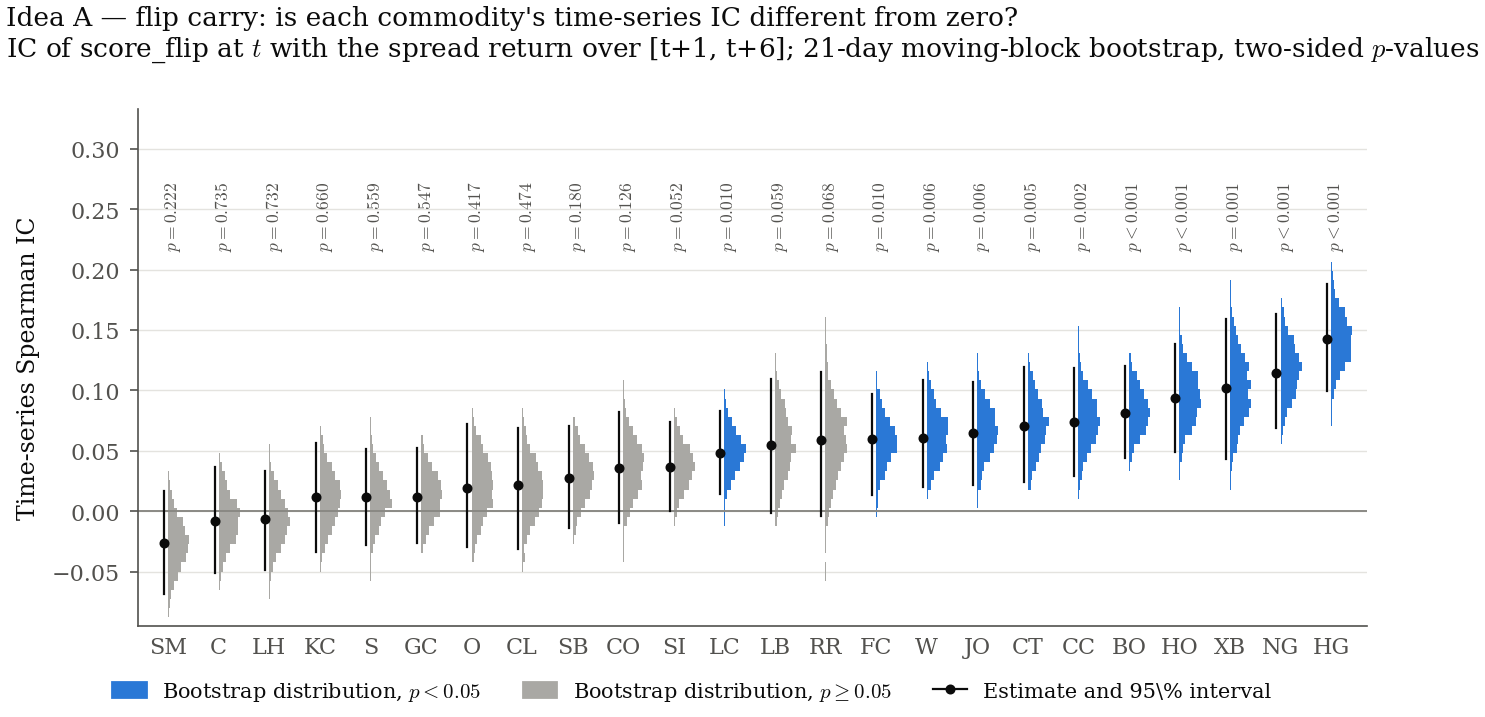

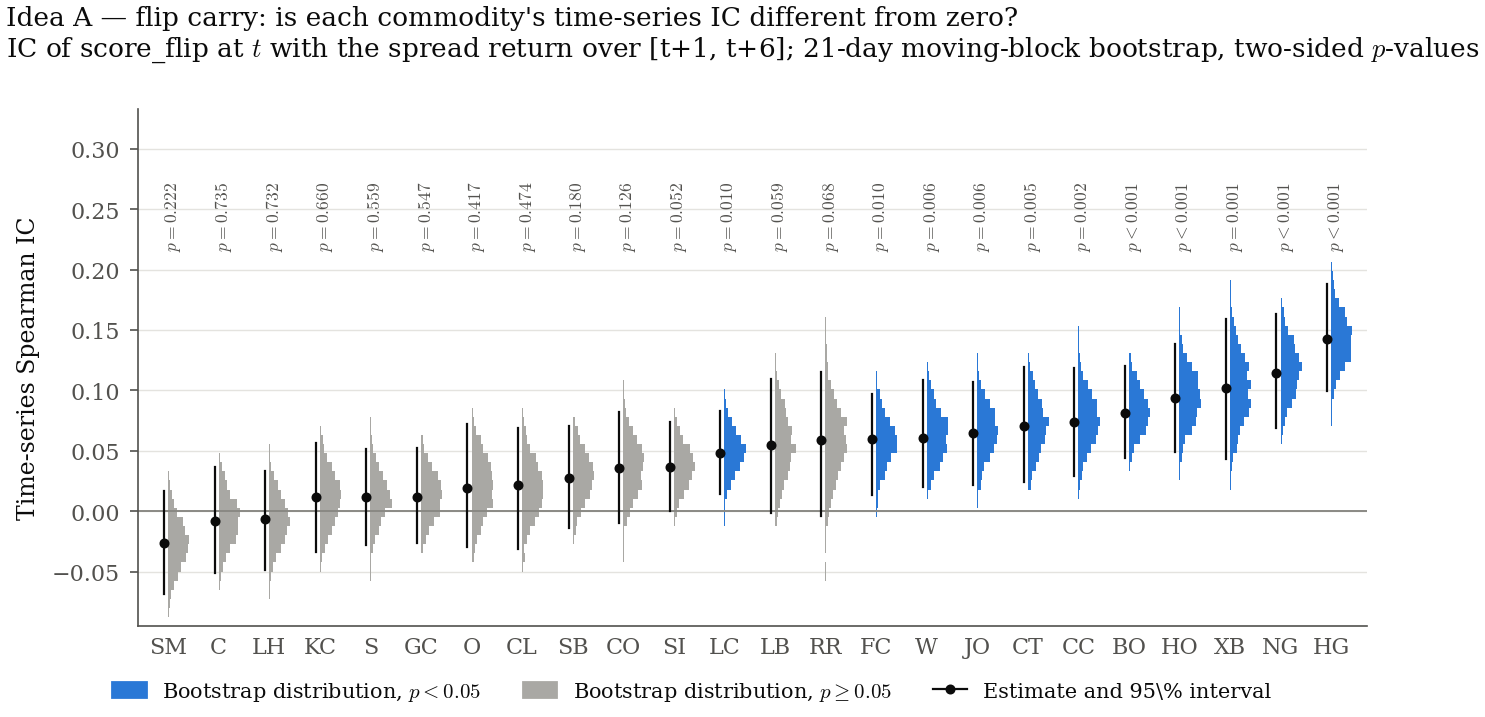

In [10]:
boot, draws = diag.bootstrap_ic_by_period(
    fwd, sig, score_col="score_flip", col="fwd_1_6",
    block=21, n_boot=2000, min_obs=252, seed=0,
)
summary = boot.groupby("period").agg(
    n_roots=("root", "nunique"),
    n_sig=("p_value", lambda s: int((s < 0.05).sum())),
    median_ic=("ic", "median"),
)
display(summary.round(3))
full = boot.loc[boot["period"].eq("full")].reset_index(drop=True)
fig = F.bootstrap_ic_distribution(
    full, draws["full"], "Idea A — flip carry", "score_flip", "[t+1, t+6]", 21
)
ps.save(fig, "idea_a_flip_ic_bootstrap")
display(fig)

### 7.5 Timing: same-settle vs t+1

`fwd_0_1` 是 paper timing（signal 和 fill 同一 settle），**不可交易**，只作
诊断；`fwd_1_2` 是 tradable timing（t close signal，t+1 fill）。两者都是
0.5x equal-notional gross。`report.execution_free_returns` 读的是
`signal["target"]`，所以这里传 `sig_flip`（target = target_flip）。

In [11]:
fwd_timing = horizon.forward_returns(pairs, inputs.marks, horizons=[(0, 1), (1, 2)])
rows = []
for label, col in (("same-settle (not tradable)", "fwd_0_1"), ("t+1 fill", "fwd_1_2")):
    r = report.execution_free_returns(fwd_timing, sig_flip, col=col)
    for period, (start, end) in diag.PERIODS.items():
        rows.append(
            {"timing": label, "period": period, **report.return_summary(r, start, end)}
        )
display(pd.DataFrame(rows).round(3))

,timing,period,ann_ret_pct,ann_vol_pct,sharpe,t_nw,days
0,same-settle (not tradable),full,0.706,0.949,0.744,4.746,10476
1,same-settle (not tradable),train 1986-2015,0.840,0.981,0.856,4.777,7698
2,same-settle (not tradable),test 2016-2026,0.336,0.855,0.394,1.211,2778
3,t+1 fill,full,0.631,0.997,0.633,4.286,10476
4,t+1 fill,train 1986-2015,0.694,1.033,0.672,4.056,7698
5,t+1 fill,test 2016-2026,0.455,0.889,0.512,1.580,2778


### 7.6 Per-root signed return and stability

`signed_returns` 用 `0.5 × target_flip × fwd_1_6`，单位 bp。每个 root 做
21-day moving-block bootstrap（2000 draws）。同样，24 个 root 不是 24 个独立
试验；这里报告 mean 的分布、CI 和 3 年滚动 mean 的正收益占比，不挑 root。

In [12]:
signed_6 = diag.signed_returns(fwd, sig_flip, col="fwd_1_6")
root_boot, root_draws = diag.per_root_signed_bootstrap_by_period(
    signed_6, block=21, n_boot=2000, min_obs=252, seed=0
)
display(root_boot.sort_values("mean").head(8).round(2))
display(
    root_boot.groupby("period").agg(
        roots=("root", "size"),
        negative_mean=("mean", lambda s: int((s < 0).sum())),
        ci_below_0=("ci_hi", lambda s: int((s < 0).sum())),
        ci_above_0=("ci_lo", lambda s: int((s > 0).sum())),
        median_mean=("mean", "median"),
    ).round(2)
)
daily = signed_6.groupby("date")["signed_bps"].mean()
rolling = daily.rolling(252 * 3).mean()
print("3-year positive share:", float((rolling.dropna() > 0).mean()))

,root,mean,ci_lo,ci_hi,p_value,n,period
49,C,-2.46,-5.69,0.37,0.11,2699,test 2016-2026
27,CL,-2.21,-4.73,0.02,0.05,7032,train 1986-2015
63,NG,-2.17,-13.72,6.63,0.64,2699,test 2016-2026
45,SM,-2.14,-4.57,0.03,0.05,6550,train 1986-2015
3,CL,-2.00,-6.05,1.02,0.22,9734,full
40,O,-1.93,-5.56,2.23,0.37,4678,train 1986-2015
21,SM,-1.67,-3.65,0.02,0.06,9246,full
51,CL,-1.44,-13.42,8.97,0.87,2702,test 2016-2026


,roots,negative_mean,ci_below_0,ci_above_0,median_mean
period,,,,,
full,24,8,0,5,0.70
test 2016-2026,24,10,0,1,0.36
train 1986-2015,24,9,0,5,0.68


3-year positive share: 0.7583581936014814


### 7.7 Test-period MDE

Sharpe/MDE 用非重叠的 `fwd_1_2`，0.5x equal-notional gross；不要用
overlapping `fwd_1_6` 的日序列年化 Sharpe。`mde_sr_80 = 2.8 / sqrt(years)`
是 80% power、双侧 5%、iid normal 的近似；autocorrelation 会让真实 MDE 更大，
所以 block-bootstrap CI 是 primary interval。

In [13]:
signed_1 = diag.signed_returns(fwd, sig_flip, col="fwd_1_2")
summary = diag.period_summary(signed_1)
summary["years"] = summary["n_days"] / 252
summary["se_sr"] = 1 / np.sqrt(summary["years"])
summary["mde_sr_80"] = 2.8 / np.sqrt(summary["years"])
display(summary[["period", "sharpe", "t_nw", "se_sr", "mde_sr_80"]].round(3))

,period,sharpe,t_nw,se_sr,mde_sr_80
0,full,0.633,4.286,0.155,0.434
1,train 1986-2015,0.672,4.056,0.181,0.507
2,test 2016-2026,0.512,1.580,0.301,0.843


### 7.8 读法 / Reading

**原始 A（motivation）：** full gross −0.484%/yr、all-in −2.610%/yr；test
gross −0.272%/yr、all-in −1.464%/yr；overall net Sharpe −2.595。原始方向是
documented negative，下面的 flip 不是它的 rescue。

**Signed profile（1x spread return）：** full 的 t+1→t+2 +0.50 bp（NW t 4.17）、
t+1→t+6 +1.30 bp（t 2.68）、t+1→t+21 +7.59 bp（t 4.61）；train 为 +0.55 /
+1.37 / +7.10 bp（t 3.87 / 2.63 / 3.99）；test 为 +0.36 / +1.10 / +8.93 bp
（t 1.63 / 0.98 / 2.36）。full/train 的短中期显著；test 方向为正，但 1d/5d
不显著，20d 的 t 2.36 是 overlapping window 的 descriptive 结果。

**IC / bins：** ALL IC full 0.048 / train 0.045 / test 0.071；per-root
bootstrap p<0.05 的个数 full 11/24、train 10/24、test 8/24。分箱的 Q5
（contango long）在 full/test/train 都是最强档（+4.88 / +5.21 / +3.87 bp）；
Q1（backwardation short）在 full/train 为负（−1.08 / −0.75 bp），在 test
为正（+2.42 bp），即 short leg 在 test 是拖累。中间三档不单调，不做
monotonicity 声明。

**Timing：** same-settle full 0.706%/yr（Sharpe 0.744，t 4.746）；t+1 fill
full 0.631%/yr（Sharpe 0.633，t 4.286）。test：same-settle 0.336%
（t 1.211），t+1 0.455%（t 1.580）。edge 没有在 t+1 后消失；但 test 的
t+1 结果不显著，不能把 same-settle 的大数字当作可交易收益。

**Breadth：** full 24 个 root 中 8 个 mean 为负、0 个 CI 在 0 以下、5 个 CI
在 0 以上；train 9/0/5；test 10/0/1。3 年滚动 mean 为正的日期占 75.8%。
test 的 breadth 明显弱于 full/train。

**Test 与 MDE（0.5x, fwd_1_2）：** full 0.631%/yr（Sharpe 0.633，NW t
4.286）；train 0.694%（0.672，4.056）；test 0.455%（0.512，1.580）。
test 的 80% MDE Sharpe 为 0.843，高于观测到的 0.512，说明 test 的样本量
不足以在 80% power 下确认这个量级；结论是 **suggestive, not confirmed**。

**Verdict：** flip carry 是 **adopted candidate signal**（D-025）。full/train
的 gross 信息为正且显著；test 方向为正但统计上不显著，不声称 test-period
alpha。§7 不含交易成本；成本、sizing 和最终 portfolio 是下一步。No test
tuning；test 是 post-hoc confirmatory slice，不是 pristine holdout。

## 8. 解读 / Reading

**原始 A 是 closed negative。** v2 正式结果不变：full-sample gross −0.484%/yr，
all-in net −2.610%/yr，overall net Sharpe −2.595；2016–2026 test gross
−0.272%/yr，all-in net −1.464%/yr。A 的原始方向不再调参，也不做 rescue 变体。

**§7 采用 flip carry 作为候选信号（D-025）。** `target_flip = -sign(spread_dollar)`：
contango → long spread，backwardation → short spread。它是新假设，不是对 A 的
rescue；官方 A 结果不变。§7 只做 gross、execution-free 的信息检验，交易成本
留到最终 portfolio。

**§7 的证据（默认参数，无 grid search）：**

- full/train 的 signed return 为正且显著；test 方向为正，但在 5% 水平上不显著
  （t+1 fill test Sharpe 0.512，NW t 1.580；80% MDE Sharpe 0.843）。
- IC 的 ALL 行 full 0.048 / train 0.045 / test 0.071；24 个 root 中 per-root
  bootstrap p<0.05 的个数 full 11 / train 10 / test 8。正 IC 支持 flip。
- 分箱显示 contango long（Q5）是最强的一档；backwardation short（Q1）在 test
  的 raw forward return 为正，即 short leg 在 test 是拖累。
- 3 年滚动 mean 为正的日期占 75.8%；test 的 per-root breadth 较弱（24 个 root
  中 10 个 mean 为负，只有 1 个 CI 在 0 以上）。
- 结论措辞：flip carry 是 adopted candidate signal；test 证据是
  **suggestive, not confirmed**，不声称 test-period alpha。

**注意：** test 2016–2026 是 post-hoc confirmatory slice，不是 pristine
pre-registered holdout，因为 flip 的 sign 是在看到 A 的 full-sample 结果后提出的；
没有参数在 test 上选择。§7 没有成本；成本、sizing 和最终组合留到 final portfolio。

- 详细负结果诊断：`docs/a_negative_result.md`。
- v1/v2 对照：`docs/v1_v2_comparison.md`。
- 旧 notebook 已 retired；恢复方式见 `docs/notebook_history.md`。